In [1]:
from pathlib import Path
import random

import numpy as np
import torch
from torch.utils.data import DataLoader

SEED = 42

# Fix random seeds to make experiments more reproducible.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Normal device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Set paths for files
project_dir = Path.cwd()
data_dir = project_dir / "data" / "keras_slices_data"
checkpoint_dir = project_dir / "checkpoints"
checkpoint_dir.mkdir(exist_ok=True)

# Setup constants
NUM_CLASSES = 6
PROSTATE_LABEL = 5 # Other labels can be found in dataset notebook
BATCH_SIZE = 16
# Value chosen after initial training split showed progress slowed after around 20 epochs.
# Also lines up with ~1h of training time for training restriction (A100 GPU)
EPOCHS = 20 

LEARNING_RATE = 1e-3

print("Device:", device)
print("Dataset:", data_dir)
print("Prostate label:", PROSTATE_LABEL)

Device: cuda
Dataset: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/data/keras_slices_data
Prostate label: 5


Split           Pairs   Patients
train           11460         31
validate          660          4
test              540          3
All image–mask pairs matched; no patient overlap.
Example: case_004_week_0_slice_0.nii.gz
Image: (256, 128) float32
Mask: (256, 128) int64
Normalised image mean: 0.0
Normalised image standard deviation: 1.0
Mask labels: [0 1 2 3]
Documentation files:
No documentation found beside the uploaded dataset.
Description: b''
Auxiliary information: b''
Extensions: Nifti1Extensions()
Training slices: 11460
Image batch: (16, 1, 256, 144) torch.float32
Mask batch: (16, 256, 144) torch.int64
Labels in this batch: [-100, 0, 1, 2, 3, 4, 5]


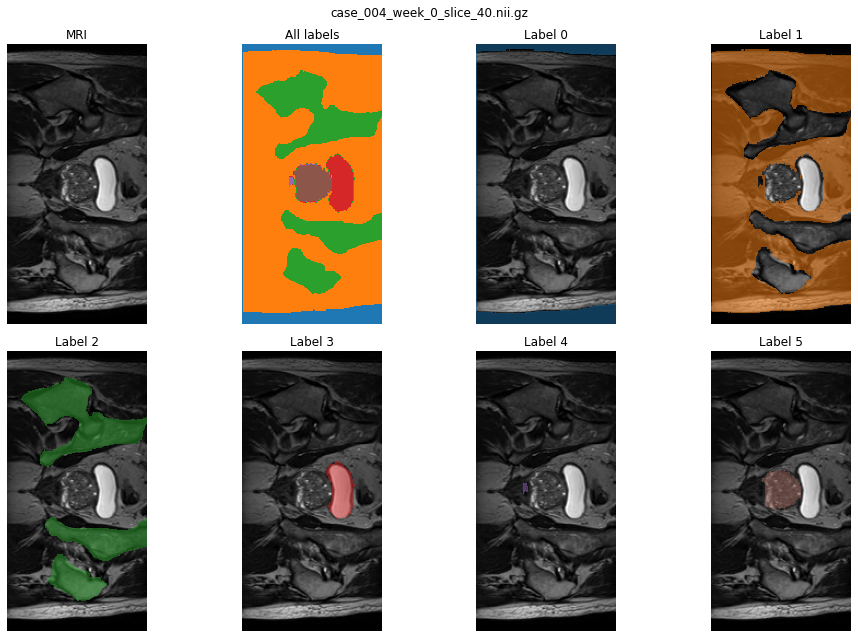

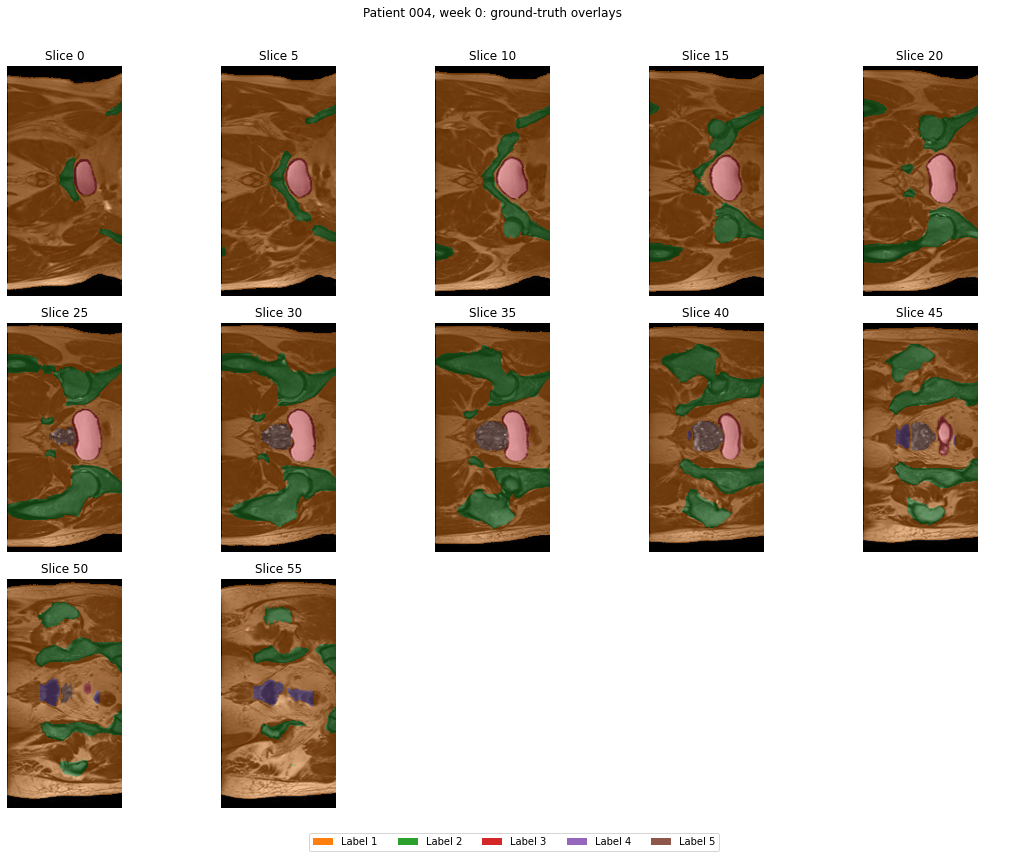

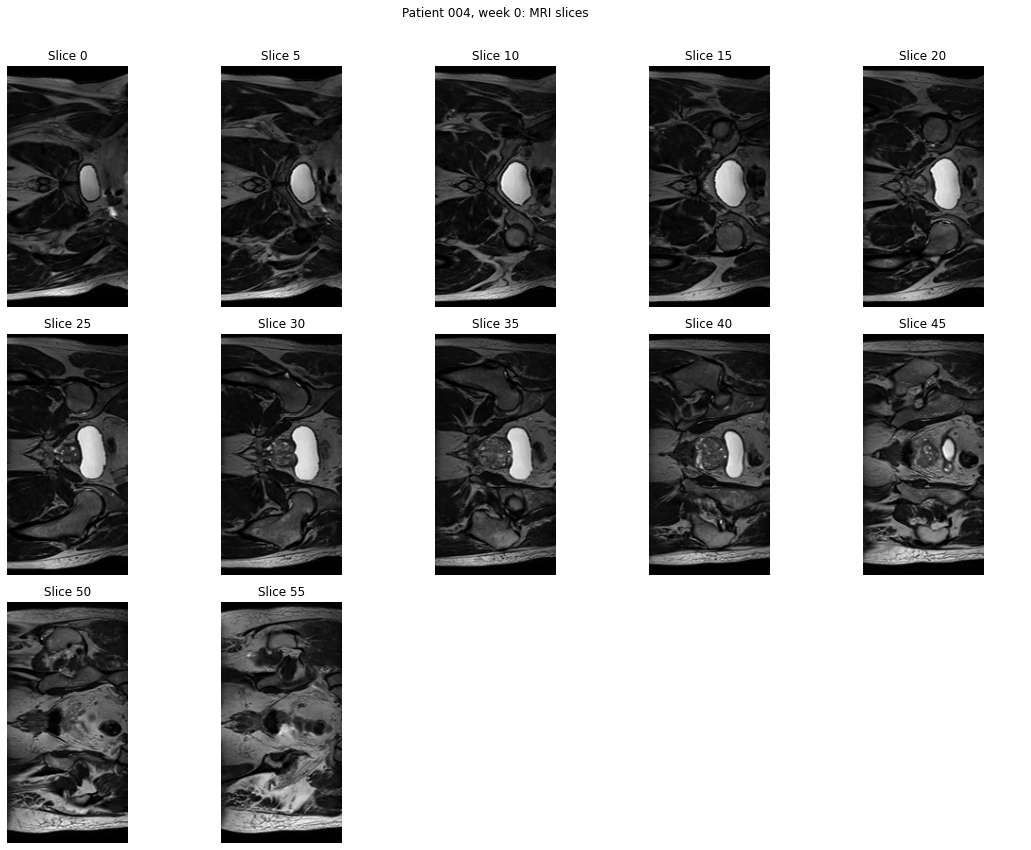

Device: cuda
Input shape: (16, 1, 256, 128)
Output shape: (16, 6, 256, 128)
Parameters: 2,158,502


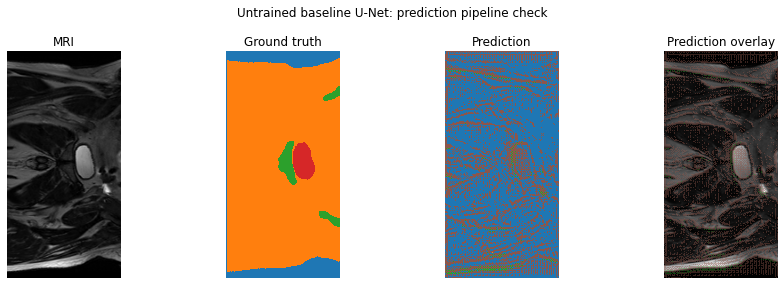

In [2]:
# Run dataset definitions and checks in this notebook's kernel.
%run ./dataset.ipynb

# Run the baseline architecture definitions.
%run ./modules.ipynb

In [7]:
class ResidualBlock(nn.Module):
    """Baseline convolution block with an added residual shortcut."""
    # Quick residual test, AI generated.

    def __init__(self, in_channels, out_channels, dropout=0):
        super().__init__()

        # Keep the baseline's convolution and dropout arrangement.
        self.layers = conv_block(in_channels, out_channels, dropout)

        # Match channel counts before adding the two paths.
        self.shortcut = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Conv2d(in_channels, out_channels, kernel_size=1)
        )

        # Initialise the new shortcut consistently with the feature layers.
        if isinstance(self.shortcut, nn.Conv2d):
            nn.init.kaiming_normal_(
                self.shortcut.weight, nonlinearity="relu"
            )
            nn.init.zeros_(self.shortcut.bias)

    def forward(self, x):
        return self.layers(x) + self.shortcut(x)


class ResidualUNet(UNet):
    """Baseline U-Net with residual encoder and bottleneck blocks."""
    # Quick residual test, AI generated.

    def __init__(self, classes=6, base=16):
        super().__init__(classes=classes, base=base)

        widths = [base * 2**i for i in range(5)]
        residual_encoders = nn.ModuleList()

        # Wrap the existing encoder blocks, preserving their initial weights.
        for i, width in enumerate(widths):
            in_channels = 1 if i == 0 else widths[i - 1]

            block = ResidualBlock(
                in_channels,
                width,
                dropout=0.3 if i >= 3 else 0,
            )
            block.layers = self.encoders[i]
            residual_encoders.append(block)

        self.encoders = residual_encoders

        # Inherit the baseline's forward method and unchanged decoder.

In [8]:
# Re-establish settings after running the dataset and modules notebooks
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)

data_dir = project_dir / "data" / "keras_slices_data"
splits = audit_splits(data_dir)

# Data loaders
# Shuffle only training data
train_loader = DataLoader(
    HipMRIDataset(splits["train"]),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

val_loader = DataLoader(
    HipMRIDataset(splits["validate"]),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

# Create a fresh residual model; do not load baseline weights.
model = ResidualUNet(classes=NUM_CLASSES, base=16).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = torch.nn.CrossEntropyLoss(ignore_index=-100)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Prostate class:", PROSTATE_LABEL)

Split           Pairs   Patients
train           11460         31
validate          660          4
test              540          3
All image–mask pairs matched; no patient overlap.
Training batches: 717
Validation batches: 42
Prostate class: 5


In [9]:
import time
import pandas as pd
from tqdm.auto import tqdm


def run_epoch(model, loader, training=False):
    model.train(training)
    loss_sum, pixel_count = 0.0, 0
    intersection, predicted_count, target_count = 0, 0, 0

    for images, masks in tqdm(loader, leave=False, mininterval=5):
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        # Enable gradients only during training.
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, masks)

            if not torch.isfinite(loss).item():
                raise RuntimeError("Non-finite loss encountered")

            if training:
                loss.backward()
                optimizer.step()

        # Exclude artificial padding from loss aggregation and Dice.
        valid = masks != -100
        pixels = valid.sum().item()
        loss_sum += loss.item() * pixels
        pixel_count += pixels

        prediction = logits.detach().argmax(dim=1)
        pred_prostate = (prediction == PROSTATE_LABEL) & valid
        true_prostate = (masks == PROSTATE_LABEL) & valid

        intersection += (pred_prostate & true_prostate).sum().item()
        predicted_count += pred_prostate.sum().item()
        target_count += true_prostate.sum().item()

    denominator = predicted_count + target_count
    dice = (
        2 * intersection / denominator
        if denominator > 0 else float("nan")
    )

    return loss_sum / pixel_count, dice

In [10]:
import time
import pandas as pd
from tqdm.auto import tqdm

# Train the residual variant.
history = []
best_dice = -1.0

checkpoint_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = checkpoint_dir / "residual_best.pt"
history_path = checkpoint_dir / "residual_history.csv"

# Start the clock measuring time budget for the training
TIME_LIMIT_SECONDS = 60 * 60
training_start = time.perf_counter()

# Track peak PyTorch GPU memory during training and validation.
if device.type == "cuda":
    torch.cuda.synchronize(device)
    torch.cuda.reset_peak_memory_stats(device)

for epoch in range(1, EPOCHS + 1):
    start = time.perf_counter()

    train_loss, train_dice = run_epoch(
        model, train_loader, training=True
    )
    val_loss, val_dice = run_epoch(
        model, val_loader, training=False
    )

    seconds = time.perf_counter() - start

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_prostate_dice": train_dice,
        "val_prostate_dice": val_dice,
        "seconds": seconds,
    })

    # Save the history before checking whether to stop.
    pd.DataFrame(history).to_csv(history_path, index=False)

    if val_dice > best_dice:
        best_dice = val_dice

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_prostate_dice": val_dice,
            "num_classes": NUM_CLASSES,
            "prostate_label": PROSTATE_LABEL,
            "base": 16,
            "target_size": (256, 144),
            "model_type": "baseline",
        }, checkpoint_path)

    elapsed = time.perf_counter() - training_start

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"loss {train_loss:.4f} / {val_loss:.4f} | "
        f"prostate Dice {train_dice:.4f} / {val_dice:.4f} | "
        f"{seconds:.1f}s | best val {best_dice:.4f} | "
        f"elapsed {elapsed / 60:.1f} min",
        flush=True,
    )

    # Stop cleanly after finishing and recording the current epoch.
    if elapsed >= TIME_LIMIT_SECONDS:
        print("One-hour training limit reached. Stopping.")
        break

if device.type == "cuda":
    print(
        "Training/validation peak allocated VRAM:",
        f"{torch.cuda.max_memory_allocated(device) / 1024**3:.3f} GiB"
    )
    print(
        "Training/validation peak reserved VRAM:",
        f"{torch.cuda.max_memory_reserved(device) / 1024**3:.3f} GiB"
    )

print("Best checkpoint:", checkpoint_path)

Epoch 01/20 | loss 0.1836 / 0.0912 | prostate Dice 0.3950 / 0.7596 | 125.2s | best val 0.7596 | elapsed 2.1 min


Epoch 02/20 | loss 0.0549 / 0.0769 | prostate Dice 0.8394 / 0.7976 | 128.4s | best val 0.7976 | elapsed 4.2 min


Epoch 03/20 | loss 0.0475 / 0.0941 | prostate Dice 0.8683 / 0.7846 | 127.6s | best val 0.7976 | elapsed 6.4 min


Epoch 04/20 | loss 0.0458 / 0.0839 | prostate Dice 0.8742 / 0.8059 | 126.7s | best val 0.8059 | elapsed 8.5 min


Epoch 05/20 | loss 0.0398 / 0.0729 | prostate Dice 0.8957 / 0.8258 | 128.8s | best val 0.8258 | elapsed 10.6 min


...

Epoch 16/20 | loss 0.0339 / 0.0942 | prostate Dice 0.9124 / 0.8161 | 125.3s | best val 0.8258 | elapsed 34.0 min


Epoch 17/20 | loss 0.0328 / 0.0846 | prostate Dice 0.9140 / 0.8213 | 132.9s | best val 0.8258 | elapsed 36.2 min


Epoch 18/20 | loss 0.0345 / 0.0845 | prostate Dice 0.9093 / 0.8208 | 132.1s | best val 0.8258 | elapsed 38.4 min


Epoch 19/20 | loss 0.0313 / 0.0918 | prostate Dice 0.9169 / 0.8255 | 150.4s | best val 0.8258 | elapsed 40.9 min


Epoch 20/20 | loss 0.0298 / 0.0810 | prostate Dice 0.9215 / 0.8211 | 167.7s | best val 0.8258 | elapsed 43.7 min
Training/validation peak allocated VRAM: 0.715 GiB
Training/validation peak reserved VRAM: 0.857 GiB
Best checkpoint: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/checkpoints/residual_best.pt


In [11]:
# Epoch 20/20 | loss 0.0298 / 0.0810 | prostate Dice 0.9215 / 0.8211 | 167.7s | best val 0.8258 | elapsed 43.7 min
# Training/validation peak allocated VRAM: 0.715 GiB
# Training/validation peak reserved VRAM: 0.857 GiB
# Best checkpoint: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/checkpoints/residual_best.pt

In [15]:
# Load the best saved weights before measuring inference.
checkpoint = torch.load(
    checkpoint_path, map_location=device, weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Select 100 validation slices spread across the validation set.
indices = np.linspace(
    0, len(val_loader.dataset) - 1,
    num=min(100, len(val_loader.dataset)),
    dtype=int,
)

# Preload inputs so timing excludes disk access and preprocessing.
# Batch size 1 measures latency for one 2D slice.
inputs = [
    val_loader.dataset[int(i)][0].unsqueeze(0)
    for i in indices
]


def synchronise():
    if device.type == "cuda":
        torch.cuda.synchronize(device)


times_ms = []

with torch.inference_mode():
    # Warm up the GPU before recording timings.
    warmup = inputs[0].to(device)
    for _ in range(10):
        _ = model(warmup).argmax(dim=1)

    synchronise()

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)

    for image in inputs:
        # Transfer before starting the timer: GPU inference only.
        image = image.to(device)
        synchronise()
        start = time.perf_counter()

        prediction = model(image).argmax(dim=1)

        synchronise()
        times_ms.append((time.perf_counter() - start) * 1000)

    # Release the final prediction and input references.
    del prediction, image, warmup

results = {
    "Model": checkpoint["model_type"],
    "Checkpoint epoch": checkpoint["epoch"],
    "Parameters": sum(p.numel() for p in model.parameters()),
    "Inference batch size": 1,
    "Slices measured": len(times_ms),
    "Mean inference time (ms/slice)": np.mean(times_ms),
    "Median inference time (ms/slice)": np.median(times_ms),
    "95th percentile time (ms/slice)": np.percentile(times_ms, 95),
}

if device.type == "cuda":
    results["Peak inference allocated VRAM (GiB)"] = (
        torch.cuda.max_memory_allocated(device) / 1024**3
    )
    results["Peak inference reserved VRAM (GiB)"] = (
        torch.cuda.max_memory_reserved(device) / 1024**3
    )

profile = pd.Series(results, name="Resource profile").to_frame()
display(profile)

# Keep measurements separately from the model weights.
profile.to_csv(checkpoint_dir / "residual_resource_profile.csv")

,Resource profile
Model,baseline
Checkpoint epoch,5
Parameters,2202534
Inference batch size,1
Slices measured,100
Mean inference time (ms/slice),2.288097
Median inference time (ms/slice),2.284822
95th percentile time (ms/slice),2.314629
Peak inference allocated VRAM (GiB),0.088145
Peak inference reserved VRAM (GiB),0.871094


In [16]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    checkpoint_dir / "residual_best.pt",
    map_location=device,
    weights_only=False,
)

preview_model = ResidualUNet(
    classes=checkpoint["num_classes"],
    base=checkpoint["base"],
).to(device)

preview_model.load_state_dict(checkpoint["model_state_dict"])
preview_model.eval()

print("Loaded best residual model from epoch:", checkpoint["epoch"])
print("Validation prostate Dice:", checkpoint["val_prostate_dice"])

Loaded best residual model from epoch: 5
Validation prostate Dice: 0.8258369362345548


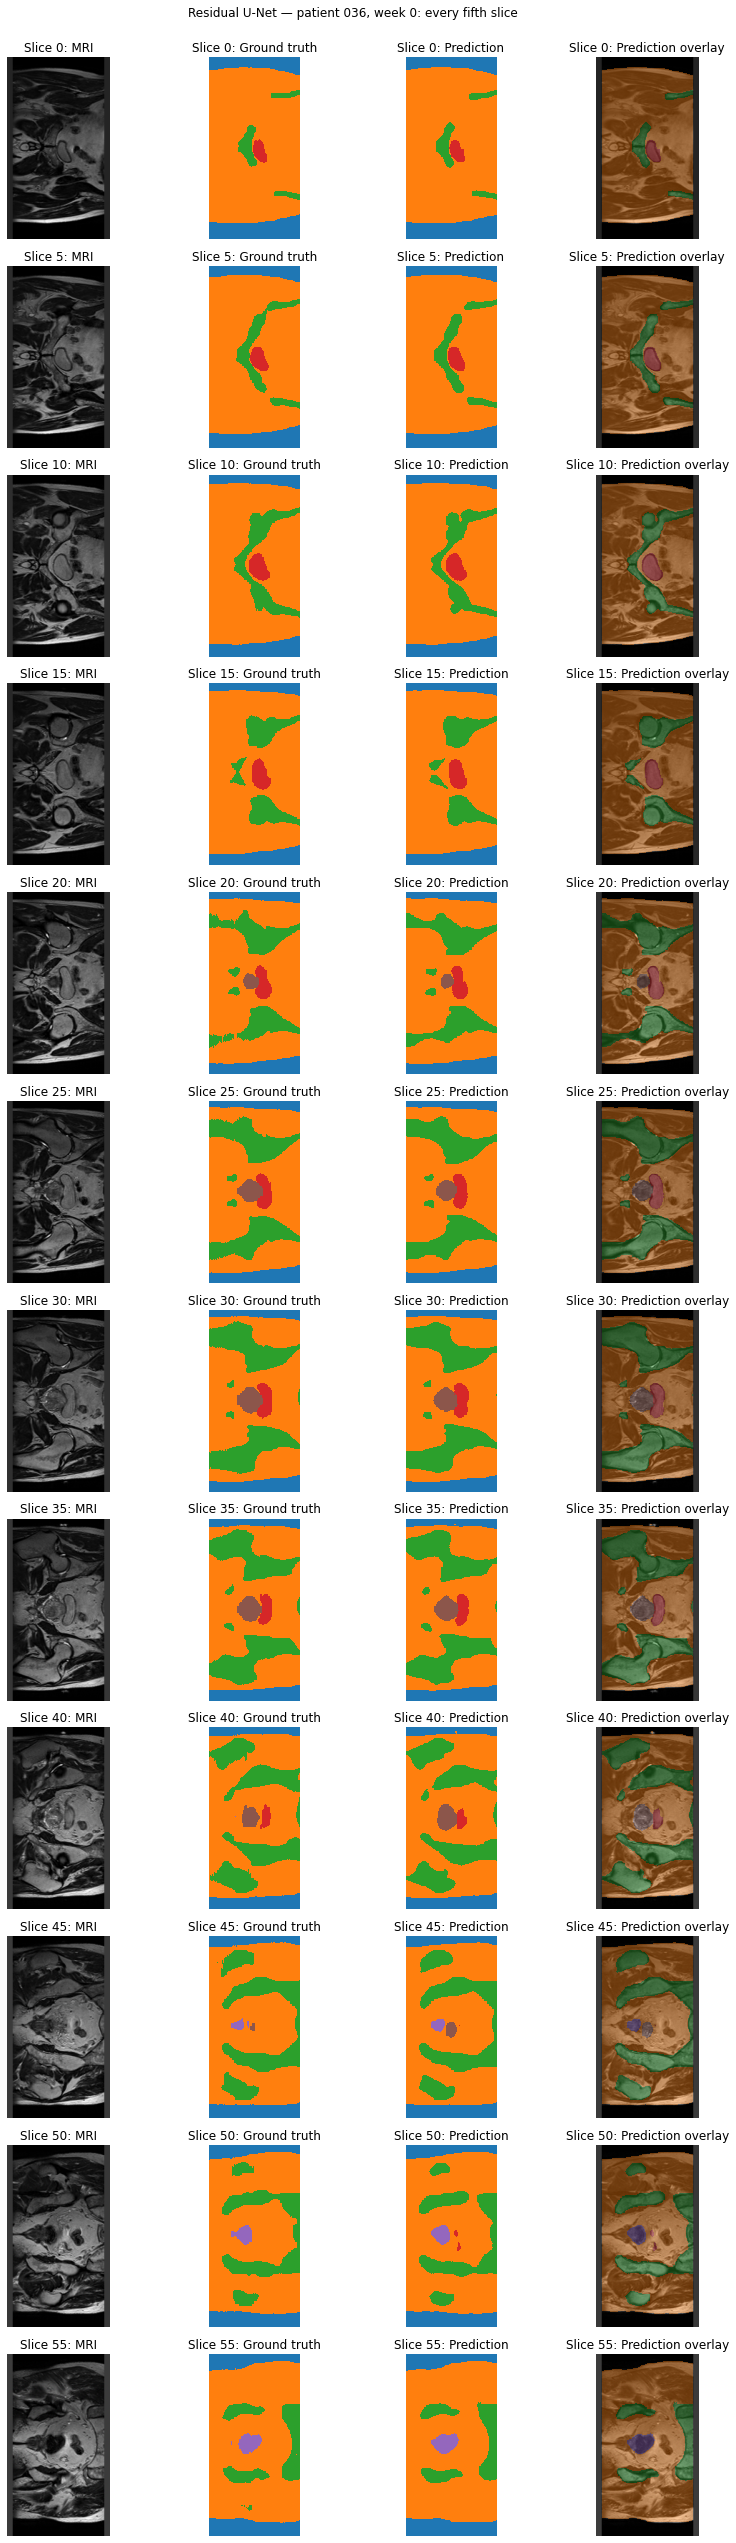

In [18]:
import matplotlib.pyplot as plt

PATIENT_ID = "036"  # Choose 036, 037, 038 or 039
WEEK = 0

# Select this patient's scan and sort slices numerically.
case_pairs = [
    pair for pair in splits["validate"]
    if pair[0].name.startswith(
        f"case_{PATIENT_ID}_week_{WEEK}_slice_"
    )
]
case_pairs.sort(
    key=lambda pair: int(pair[0].name.split("_slice_")[1].split(".")[0])
)

selected = case_pairs[::5]
assert selected, "No matching slices found."

# Reuse the dataset preprocessing, including padding.
preview_dataset = HipMRIDataset(selected)

fig, axes = plt.subplots(
    len(selected), 4,
    figsize=(12, 3 * len(selected)),
    squeeze=False,
)
colours = dict(cmap="tab10", vmin=0, vmax=9, interpolation="nearest")

preview_model.eval()

for row, (image_path, _) in enumerate(selected):
    image, mask = preview_dataset[row]
    slice_number = image_path.name.split("_slice_")[1].split(".")[0]

    with torch.no_grad():
        prediction = preview_model(image.unsqueeze(0).to(device))
        prediction = prediction.argmax(dim=1)[0].cpu().numpy()

    image = image[0].numpy()
    mask = mask.numpy()
    valid = mask != -100

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 1].imshow(np.ma.masked_where(~valid, mask), **colours)
    axes[row, 2].imshow(
        np.ma.masked_where(~valid, prediction), **colours
    )

    axes[row, 3].imshow(image, cmap="gray")
    axes[row, 3].imshow(
        np.ma.masked_where((prediction == 0) | ~valid, prediction),
        alpha=0.4,
        **colours,
    )

    for ax, title in zip(
        axes[row],
        ["MRI", "Ground truth", "Prediction", "Prediction overlay"],
    ):
        ax.set_title(f"Slice {slice_number}: {title}")
        ax.axis("off")

fig.suptitle(
    f"Residual U-Net — patient {PATIENT_ID}, week {WEEK}: every fifth slice")
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()